# Vẽ Gradient Descent cho hàm một biến f(x) = x^2 + 5 sin(x) (mục 5.1.3)

với hai điểm khởi tạo x0 = -5 và x0 = 5, cùng tốc độ học η = 0.1

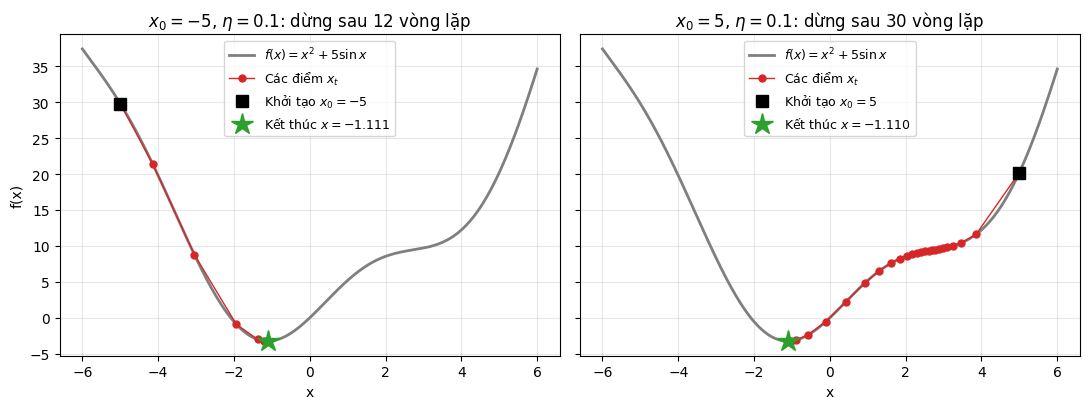

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

def f(x):
    return x**2 + 5 * np.sin(x)

def grad(x):
    """Đạo hàm f'(x)."""
    return 2 * x + 5 * np.cos(x)

def gd(x0, eta, max_iter=100, tol=1e-3):
    """GD từ x0, dừng khi |f'(x)| < tol; trả về dãy x qua các vòng lặp."""
    x = x0
    history = [x0]
    for _ in range(max_iter):
        x = x - eta * grad(x)
        history.append(x)
        if abs(grad(x)) < tol:
            break
    return np.array(history)

x_line = np.linspace(-6, 6, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, x0 in zip(axes, [-5, 5]):
    x_history = gd(x0, 0.1)
    ax.plot(x_line, f(x_line), color="#7F7F7F", lw=2, label=r"$f(x) = x^2 + 5\sin x$")
    ax.plot(x_history, f(x_history), "o-", color="#D62728", ms=5, lw=1, label="Các điểm $x_t$")
    ax.plot(x_history[0], f(x_history[0]), "s", color="black", ms=9, label=f"Khởi tạo $x_0 = {x0}$")
    ax.plot(x_history[-1], f(x_history[-1]), "*", color="#2CA02C", ms=16,
            label=f"Kết thúc $x = {x_history[-1]:.3f}$")
    ax.set_title(f"$x_0 = {x0}$, $\\eta = 0.1$: dừng sau {len(x_history) - 1} vòng lặp")
    ax.set_xlabel("x"); ax.grid(alpha=0.3)
    ax.legend(loc="upper center", fontsize=9)
axes[0].set_ylabel("f(x)")
fig.tight_layout()
fig.savefig(IMAGES / "gd_1d.png", dpi=150)